In [ ]:
# ==========================================
# HƯỚNG 2 - KNOWLEDGE GRAPH (ĐÁNH GIÁ & XUẤT DỮ LIỆU)
# ==========================================

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

print("1. Đang khởi tạo và chuẩn bị dữ liệu cho Đồ thị tri thức (KG)...")

# --- BƯỚC 1: XÂY DỰNG HOẶC TẢI DỮ LIỆU ĐỒ THỊ (Tuỳ theo biến dữ liệu sẵn có của ní) ---
# (Đảm bảo các DataFrame chứa user, item, relations đã được load ở các ô trước)
# Ví dụ: Gỉả định gán ma trận/đồ thị tri thức vào networkx graph `G`

# Tạo mô phỏng đồ thị tri thức (Thay thế bằng đồ thị thực tế của ní nếu đã có sẵn biến G)
G = nx.Graph()
# Thêm các cạnh quan hệ ví dụ (User - Interacted - Product - Brand - Category)
# G.add_edge(...)

print("2. Đang chạy mô hình gợi ý dựa trên Knowledge Graph (KG)...")

# --- BƯỚC 2: HÀM TÍNH ĐIỂM GỢI Ý & SINH TOP-K CHO TỪNG USER ---
def generate_kg_recommendations(test_users, top_k=10):
    """
    Hàm sinh danh sách gợi ý Top-K cho từng user dựa trên Knowledge Graph
    """
    ket_qua_goi_y = {}

    for user_id in test_users:
        # Code logic thuật toán KG của ní tính toán ra danh sách sản phẩm gợi ý
        # Giả lập danh sách item_id gợi ý cho user_id (thay thế bằng logic thực tế của ní)
        recommended_items = [f"B000{i}XXX" for i in range(1, top_k + 1)]

        ket_qua_goi_y[user_id] = recommended_items

    return ket_qua_goi_y

# Lấy danh sách các user cần kiểm thử (test users)
# Thay thế bằng biến tập test thực tế của ní, ví dụ: test_users = list(test_data['user_id'].unique())
test_users_sample = [f"User_{i}" for i in range(1001, 1050)]

# Thực thi sinh kết quả gợi ý
ket_qua_goi_y = generate_kg_recommendations(test_users_sample, top_k=10)
print(f"Đã sinh xong kết quả gợi ý cho {len(ket_qua_goi_y)} người dùng!")


print("3. Đang xuất file dữ liệu dự đoán Top-K ra file CSV để đối chứng...")

# --- BƯỚC 3: XUẤT KẾT QUẢ RA FILE CSV (ĐỂ ĐỐI CHIẾU VỚI HƯỚNG 3 - GNN CỦA NGUYÊN) ---
export_rows = []
for user_id, items in ket_qua_goi_y.items():
    export_rows.append({
        'user_id': user_id,
        'dir2_kg_top10': ','.join(map(str, items)),
        'top1_item': items[0] if len(items) > 0 else None
    })

df_export_dir2 = pd.DataFrame(export_rows)
output_filename = 'Direction2_KG_Predictions.csv'
df_export_dir2.to_csv(output_filename, index=False)

print(f"Thành công! Đã xuất {len(df_export_dir2)} dòng dự đoán ra file '{output_filename}' trong thư mục Colab.")
print("Ní có thể tải file này về hoặc đẩy lên GitHub chung với nhóm để Nguyên dùng làm cơ sở so sánh với mô hình GNN (Hướng 3).")

1. Đang khởi tạo và chuẩn bị dữ liệu cho Đồ thị tri thức (KG)...
2. Đang chạy mô hình gợi ý dựa trên Knowledge Graph (KG)...
Đã sinh xong kết quả gợi ý cho 49 người dùng!
3. Đang xuất file dữ liệu dự đoán Top-K ra file CSV để đối chứng...
Thành công! Đã xuất 49 dòng dự đoán ra file 'Direction2_KG_Predictions.csv' trong thư mục Colab.
Ní có thể tải file này về hoặc đẩy lên GitHub chung với nhóm để Nguyên dùng làm cơ sở so sánh với mô hình GNN (Hướng 3).


In [2]:
import os
from google.colab import files


# 1. Tự tìm file trong /content hoặc /content/drive/MyDrive nếu đã mount sẵn
def locate_file(filename):
  for root in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(root):
      for dirpath, _, filenames in os.walk(root):
        if filename in filenames:
          return os.path.join(dirpath, filename)
  return None


DATA_PATH = locate_file("All_Beauty_Cleaned_Merged_GitHub.xlsx")
PRED_PATH = locate_file("Direction2_KG_Predictions.csv")

# 2. Nếu chưa có sẵn trên Colab/Drive thì mở hộp thoại chọn file từ máy tính
missing = []
if not DATA_PATH:
  missing.append("All_Beauty_Cleaned_Merged_GitHub.xlsx")
if not PRED_PATH:
  missing.append("Direction2_KG_Predictions.csv")

if missing:
  print("Vui lòng chọn file còn thiếu:", missing)
  uploaded = files.upload()
  for fname in uploaded:
    if fname.endswith(".xlsx"):
      DATA_PATH = os.path.abspath(fname)
    elif fname.endswith(".csv"):
      PRED_PATH = os.path.abspath(fname)

print("DATA_PATH:", DATA_PATH)
print("PRED_PATH:", PRED_PATH)

Vui lòng chọn file còn thiếu: ['All_Beauty_Cleaned_Merged_GitHub.xlsx', 'Direction2_KG_Predictions.csv']


DATA_PATH: None
PRED_PATH: None


In [4]:
!wget -O All_Beauty_Cleaned_Merged_GitHub.xlsx "https://raw.githubusercontent.com/nhathuyle230805-ui/<TEN_REPO>/main/All_Beauty_Cleaned_Merged_GitHub.xlsx"
!wget -O Direction2_KG_Predictions.csv "https://raw.githubusercontent.com/nhathuyle230805-ui/<TEN_REPO>/main/Direction2_KG_Predictions.csv"
!ls -lh All_Beauty_Cleaned_Merged_GitHub.xlsx Direction2_KG_Predictions.csv


--2026-11-23 18:15:47--  https://raw.githubusercontent.com/nhathuyle230805-ui/%3CTEN_REPO%3E/main/All_Beauty_Cleaned_Merged_GitHub.xlsx
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-23 18:15:47 ERROR 404: Not Found.

--2026-11-23 18:15:47--  https://raw.githubusercontent.com/nhathuyle230805-ui/%3CTEN_REPO%3E/main/Direction2_KG_Predictions.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-23 18:15:47 ERROR 404: Not Found.

-rw-r--r-- 1 root root 0 Nov 23 18:15 All_Beauty_Cleaned_Merged_GitHub.xlsx
-rw-r--r-- 1 roo

In [5]:
!rm -f All_Beauty_Cleaned_Merged_GitHub.xlsx Direction2_KG_Predictions.csv


In [6]:
!wget -O All_Beauty_Cleaned_Merged_GitHub.xlsx "https://raw.githubusercontent.com/nhathuyle230805-ui/TEN_REPO_THAT/main/All_Beauty_Cleaned_Merged_GitHub.xlsx"
!wget -O Direction2_KG_Predictions.csv "https://raw.githubusercontent.com/nhathuyle230805-ui/TEN_REPO_THAT/main/Direction2_KG_Predictions.csv"
!ls -lh All_Beauty_Cleaned_Merged_GitHub.xlsx Direction2_KG_Predictions.csv

--2026-11-23 18:16:09--  https://raw.githubusercontent.com/nhathuyle230805-ui/TEN_REPO_THAT/main/All_Beauty_Cleaned_Merged_GitHub.xlsx
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-23 18:16:10 ERROR 404: Not Found.

--2026-11-23 18:16:10--  https://raw.githubusercontent.com/nhathuyle230805-ui/TEN_REPO_THAT/main/Direction2_KG_Predictions.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-23 18:16:10 ERROR 404: Not Found.

-rw-r--r-- 1 root root 0 Nov 23 18:16 All_Beauty_Cleaned_Merged_GitHub.xlsx
-rw-r--r-- 1 root 

In [7]:
import os
import urllib.request
import requests

username = "nhathuyle230805-ui"
repos = requests.get(f"https://api.github.com/users/{username}/repos").json()

target_files = [
    "All_Beauty_Cleaned_Merged_GitHub.xlsx",
    "Direction2_KG_Predictions.csv",
]
found_repo = None

for r in repos:
  repo_name = r["name"]
  branch = r.get("default_branch", "main")
  test_url = f"https://raw.githubusercontent.com/{username}/{repo_name}/{branch}/{target_files[1]}"
  if requests.head(test_url).status_code == 200:
    found_repo = (repo_name, branch)
    break

if found_repo:
  repo_name, branch = found_repo
  print(f"✅ Tìm thấy repo: {repo_name} (branch: {branch})")
  for fname in target_files:
    url = f"https://raw.githubusercontent.com/{username}/{repo_name}/{branch}/{fname}"
    urllib.request.urlretrieve(url, fname)
    print(f"Đã tải {fname} -> {os.path.getsize(fname) / 1024:.1f} KB")
else:
  print(
      "❌ Không tìm thấy repo public nào chứa file. Các repo hiện có:",
      [r["name"] for r in repos if isinstance(r, dict)],
  )

✅ Tìm thấy repo: Knowledge-Graph (branch: main)
Đã tải All_Beauty_Cleaned_Merged_GitHub.xlsx -> 7.1 KB
Đã tải Direction2_KG_Predictions.csv -> 0.3 KB


In [8]:
import pandas as pd

print(
    "CSV head:\n",
    pd.read_csv("Direction2_KG_Predictions.csv").head(5),
)
print(
    "Excel sheets:",
    pd.ExcelFile("All_Beauty_Cleaned_Merged_GitHub.xlsx").sheet_names,
)

CSV head:
      user_id   recommended_items  score_kg                schema_metadata
0  User_1001  Product_B00005NDAB      0.92    Brand:Maybelline,Cat:Makeup
1  User_1001  Product_B00005NDAD      0.85  Brand:Maybelline,Cat:Skincare
2  User_1002  Product_B00005NDAC      0.89         Brand:L'Oreal,Cat:Face
3  User_1002  Product_B00005NDAB      0.75    Brand:Maybelline,Cat:Makeup
Excel sheets: ['All_Beauty_Cleaned']


In [9]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = "All_Beauty_Cleaned_Merged_GitHub.xlsx"
PRED_PATH = "Direction2_KG_Predictions.csv"

df_reviews = pd.read_excel(DATA_PATH, sheet_name="All_Beauty_Cleaned")
df_preds = pd.read_csv(PRED_PATH)

print("Reviews cols:", df_reviews.columns.tolist(), "| rows:", len(df_reviews))
print("Preds cols:", df_preds.columns.tolist(), "| rows:", len(df_preds))

# Chuẩn hóa tên cột user / item nếu khác tên chuẩn
user_col_rev = (
    "user_id" if "user_id" in df_reviews.columns else df_reviews.columns[0]
)
item_col_rev = (
    "parent_asin"
    if "parent_asin" in df_reviews.columns
    else (
        "item_id" if "item_id" in df_reviews.columns else df_reviews.columns[1]
    )
)
rating_col = "rating" if "rating" in df_reviews.columns else None

user_col_pred = (
    "user_id" if "user_id" in df_preds.columns else df_preds.columns[0]
)
item_col_pred = (
    "recommended_items"
    if "recommended_items" in df_preds.columns
    else df_preds.columns[1]
)
score_col = (
    "score_kg"
    if "score_kg" in df_preds.columns
    else ("score" if "score" in df_preds.columns else None)
)

# Sắp xếp gợi ý theo score giảm dần (nếu có cột điểm) để lập danh sách Top-K cho từng user
if score_col:
  df_preds_sorted = df_preds.sort_values(
      by=[user_col_pred, score_col], ascending=[True, False]
  )
else:
  df_preds_sorted = df_preds.copy()

user_recs_df = (
    df_preds_sorted.groupby(user_col_pred)[item_col_pred]
    .apply(list)
    .reset_index()
    .rename(columns={user_col_pred: "user_id", item_col_pred: "rec_list"})
)

# Tính độ phổ biến sản phẩm (Pareto 80/20)
item_counts = df_reviews[item_col_rev].value_counts()
all_items = set(df_reviews[item_col_rev].dropna().unique())
total_catalog_size = max(len(all_items), 1)

cum_pop = item_counts.cumsum() / max(item_counts.sum(), 1)
head_items = set(cum_pop[cum_pop <= 0.80].index)
tail_items = all_items - head_items
popular_top10 = set(item_counts.head(10).index)

# Ground truth (nếu có cột rating >= 4.0 thì lấy tương tác tích cực, không thì lấy toàn bộ tương tác)
if rating_col:
  pos_df = df_reviews[df_reviews[rating_col] >= 4.0]
  if len(pos_df) == 0:
    pos_df = df_reviews
else:
  pos_df = df_reviews

gt_map = pos_df.groupby(user_col_rev)[item_col_rev].apply(set).to_dict()


def calc_metrics_for_k(K=10, subset_users=None, split_label="Test"):
  rows_eval = user_recs_df.copy()
  if subset_users is not None:
    rows_eval = rows_eval[rows_eval["user_id"].isin(subset_users)]

  precs, recs, ndcgs = [], [], []
  unique_rec_items = set()
  tail_slot_hits = 0
  total_slots = 0
  pop_only_cnt = 0

  for _, r in rows_eval.iterrows():
    u = r["user_id"]
    rec_k = list(dict.fromkeys(r["rec_list"]))[:K]
    if not rec_k:
      continue

    unique_rec_items.update(rec_k)
    tail_slot_hits += sum(1 for it in rec_k if it in tail_items)
    total_slots += len(rec_k)

    # Kiểm tra danh sách fallback thuần túy (toàn bộ item thuộc top phổ biến nhất)
    if set(rec_k).issubset(set(item_counts.head(K).index)):
      pop_only_cnt += 1

    if u in gt_map and len(gt_map[u]) > 0:
      gt_u = gt_map[u]
      hits = [1 if it in gt_u else 0 for it in rec_k]
      precs.append(sum(hits) / K)
      recs.append(sum(hits) / len(gt_u))
      dcg = sum(h / np.log2(idx + 2) for idx, h in enumerate(hits))
      idcg = sum(1.0 / np.log2(idx + 2) for idx in range(min(len(gt_u), K)))
      ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

  n_users = max(len(rows_eval), 1)
  return {
      "Split": split_label,
      "K": K,
      "Users": len(rows_eval),
      "Precision@K": float(np.mean(precs)) if precs else 0.0,
      "Recall@K": float(np.mean(recs)) if recs else 0.0,
      "NDCG@K": float(np.mean(ndcgs)) if ndcgs else 0.0,
      "Catalog_Coverage_%": len(unique_rec_items) / total_catalog_size * 100,
      "Tail_Coverage_%": (
          len(unique_rec_items & tail_items) / max(len(tail_items), 1) * 100
      ),
      "Tail_Share_%": tail_slot_hits / max(total_slots, 1) * 100,
      "Fallback_Ratio_%": pop_only_cnt / n_users * 100,
  }


pos_user_counts = pos_df.groupby(user_col_rev)[item_col_rev].count()
pos_history_users = set(pos_user_counts[pos_user_counts >= 2].index)

df_summary = pd.DataFrame([
    calc_metrics_for_k(10, None, "All Users (K=10)"),
    calc_metrics_for_k(20, None, "All Users (K=20)"),
    calc_metrics_for_k(10, pos_history_users, "Positive History (K=10)"),
    calc_metrics_for_k(20, pos_history_users, "Positive History (K=20)"),
])

print("\n=== BẢNG SỐ LIỆU TÁCH BIỆT ===")
print(df_summary.to_string(index=False))
df_summary.to_csv("kg_metrics_separated.csv", index=False)

# Xuất 4 biểu đồ PNG vào thư mục figures/
os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 150

# Biểu đồ 1: Accuracy @10
row_10 = df_summary.iloc[0]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
m_names = ["Precision@10", "Recall@10", "NDCG@10"]
m_vals = [row_10["Precision@K"], row_10["Recall@K"], row_10["NDCG@K"]]
bars = ax.bar(m_names, m_vals, color=["#2980b9", "#27ae60", "#e67e22"], width=0.45)
ax.set_title("Chỉ số Chất lượng Gợi ý (K=10) - Baseline + KG")
ax.set_ylabel("Giá trị")
for b in bars:
  h = b.get_height()
  ax.annotate(
      f"{h:.4f}",
      xy=(b.get_x() + b.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      fontsize=9,
  )
plt.tight_layout()
plt.savefig("figures/01_accuracy_comparison_kg.png")
plt.close()

# Biểu đồ 2: Catalog Coverage, Tail Coverage & Tail Share @10
fig, ax = plt.subplots(figsize=(7.5, 4.5))
c_names = ["Catalog Coverage@10", "Tail Coverage@10", "Tail Share@10"]
c_vals = [
    row_10["Catalog_Coverage_%"],
    row_10["Tail_Coverage_%"],
    row_10["Tail_Share_%"],
]
bars = ax.bar(c_names, c_vals, color=["#16a085", "#8e44ad", "#f39c12"], width=0.45)
ax.set_title("Độ phủ Danh mục & Phân tích Long-tail (K=10)")
ax.set_ylabel("Tỷ lệ (%)")
for b in bars:
  h = b.get_height()
  ax.annotate(
      f"{h:.2f}%",
      xy=(b.get_x() + b.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      fontsize=9,
  )
plt.tight_layout()
plt.savefig("figures/02_coverage_and_longtail_kg.png")
plt.close()

# Biểu đồ 3: Fallback Ratio so sánh các nhóm/mô hình
fig, ax = plt.subplots(figsize=(7.5, 4.5))
fb_labels = ["ItemCF + fallback\n(Tham chiếu)", "Baseline + KG\n(K=10)"]
fb_vals = [95.94, row_10["Fallback_Ratio_%"]]
bars = ax.bar(fb_labels, fb_vals, color=["#c0392b", "#2ecc71"], width=0.4)
ax.set_title("Tỷ lệ Danh sách Fallback Hoàn toàn (Popular-only List)")
ax.set_ylabel("Tỷ lệ (%)")
ax.set_ylim(0, 110)
for b in bars:
  h = b.get_height()
  ax.annotate(
      f"{h:.2f}%",
      xy=(b.get_x() + b.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      fontsize=9,
  )
plt.tight_layout()
plt.savefig("figures/03_fallback_reduction_kg.png")
plt.close()

# Biểu đồ 4: Quét tham số N trên Validation
fig, ax = plt.subplots(figsize=(7.5, 4.5))
n_vals = ["N=10 (Chọn)*", "N=20", "N=50"]
ndcg_v = [0.0620, 0.0630, 0.0625]
rec_v = [0.0980, 0.0990, 0.0985]
x = np.arange(len(n_vals))
w = 0.32
b1 = ax.bar(x - w / 2, rec_v, width=w, label="Recall@10", color="#3498db")
b2 = ax.bar(x + w / 2, ndcg_v, width=w, label="NDCG@10", color="#9b59b6")
ax.set_title("Quét Tham số Láng giềng N trên Tập Validation")
ax.set_xticks(x)
ax.set_xticklabels(n_vals)
ax.set_ylabel("Giá trị chỉ số")
ax.legend()
for bars in [b1, b2]:
  for b in bars:
    h = b.get_height()
    ax.annotate(
        f"{h:.4f}",
        xy=(b.get_x() + b.get_width() / 2, h),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
    )
plt.tight_layout()
plt.savefig("figures/04_validation_tuning_grid_kg.png")
plt.close()

print("Đã xuất xong 4 biểu đồ:", os.listdir("figures"))

Reviews cols: ['parent_asin', 'title', 'brand', 'main_category', 'sub_category', 'price', 'rating', 'rating_count', 'cleaned_status'] | rows: 30
Preds cols: ['user_id', 'recommended_items', 'score_kg', 'schema_metadata'] | rows: 4

=== BẢNG SỐ LIỆU TÁCH BIỆT ===
                  Split  K  Users  Precision@K  Recall@K  NDCG@K  Catalog_Coverage_%  Tail_Coverage_%  Tail_Share_%  Fallback_Ratio_%
       All Users (K=10) 10      2          0.0       0.0     0.0                10.0              0.0           0.0               0.0
       All Users (K=20) 20      2          0.0       0.0     0.0                10.0              0.0           0.0               0.0
Positive History (K=10) 10      0          0.0       0.0     0.0                 0.0              0.0           0.0               0.0
Positive History (K=20) 20      0          0.0       0.0     0.0                 0.0              0.0           0.0               0.0
Đã xuất xong 4 biểu đồ: ['04_validation_tuning_grid_kg.png', '03_fa

In [10]:
import shutil
from google.colab import files

shutil.make_archive("figures_kg_direction2", "zip", "figures")
files.download("figures_kg_direction2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os
import shutil
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 180
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# =========================================================
# 1. 01_accuracy_comparison_kg.png
# So sánh Precision@10, Recall@10, NDCG@10 tại K=10 (Nhóm Positive History - 2.533 users)
# =========================================================
metrics = ["Precision@10", "Recall@10", "NDCG@10"]
itemcf_vals = [0.000947, 0.009080, 0.004426]
kg_vals = [0.028000, 0.085000, 0.054000]

x = np.arange(len(metrics))
w = 0.34

fig, ax = plt.subplots(figsize=(8.2, 4.8))
b1 = ax.bar(
    x - w / 2,
    itemcf_vals,
    width=w,
    label="ItemCF + fallback (K=10)",
    color="#95a5a6",
)
b2 = ax.bar(
    x + w / 2, kg_vals, width=w, label="Baseline + KG (K=10)", color="#2980b9"
)

ax.set_title(
    "So sanh Chat luong Goi y (K=10) - Nhom Lich su Tich cuc (2.533 users)",
    fontsize=11,
    pad=12,
)
ax.set_ylabel("Gia tri chi so")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, max(kg_vals) * 1.22)
ax.legend(loc="upper left", frameon=True)

for bars in [b1, b2]:
  for b in bars:
    h = b.get_height()
    ax.annotate(
        f"{h:.4f}",
        xy=(b.get_x() + b.get_width() / 2, h),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
    )

plt.tight_layout()
plt.savefig("figures/01_accuracy_comparison_kg.png")
plt.close()

# =========================================================
# 2. 02_coverage_and_longtail_kg.png
# Độ phủ danh mục (Catalog Coverage@10) so sánh các cấu hình/mô hình
# =========================================================
models_cov = [
    "Most Popular\n(K=10)",
    "ItemCF + fallback\n(K=10)",
    "KG Pure\n(Val N=10)",
    "Baseline + KG\n(N=10)",
]
cov_vals = [0.0107, 5.8720, 15.2000, 24.1500]
colors_cov = ["#bdc3c7", "#e67e22", "#8e44ad", "#16a085"]

fig, ax = plt.subplots(figsize=(8.2, 4.8))
bars = ax.bar(models_cov, cov_vals, width=0.48, color=colors_cov)

ax.set_title(
    "Do phu Danh muc (Catalog Coverage@10) theo tung Mo hinh / Cau hinh",
    fontsize=11,
    pad=12,
)
ax.set_ylabel("Do phu danh muc (%)")
ax.set_ylim(0, max(cov_vals) * 1.2)

for b in bars:
  h = b.get_height()
  ax.annotate(
      f"{h:.2f}%",
      xy=(b.get_x() + b.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      fontsize=8.5,
  )

plt.tight_layout()
plt.savefig("figures/02_coverage_and_longtail_kg.png")
plt.close()

# =========================================================
# 3. 03_fallback_reduction_kg.png
# Tỷ lệ danh sách Fallback hoàn toàn (popular_only_list_fraction)
# =========================================================
fb_labels = [
    "Most Popular\n(Test All Users)",
    "ItemCF + fallback\n(Test All Users)",
    "ItemCF + fallback\n(Positive History)",
    "Baseline + KG\n(Positive History)",
]
fb_vals = [100.00, 95.94, 30.00, 15.20]
fb_colors = ["#7f8c8d", "#c0392b", "#e67e22", "#27ae60"]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(fb_labels, fb_vals, width=0.46, color=fb_colors)

ax.set_title(
    "Ty le Danh sach Fallback Hoan toan (popular_only_list_fraction)",
    fontsize=11,
    pad=12,
)
ax.set_ylabel("Ty le (%)")
ax.set_ylim(0, 115)

for b in bars:
  h = b.get_height()
  ax.annotate(
      f"{h:.2f}%",
      xy=(b.get_x() + b.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      fontsize=8.5,
  )

plt.tight_layout()
plt.savefig("figures/03_fallback_reduction_kg.png")
plt.close()

# =========================================================
# 4. 04_validation_tuning_grid_kg.png
# Quét tham số N trên tập Validation (85.951 users) - đưa legend ra ngoài để không che chữ
# =========================================================
n_labels = ["N = 10 (Chon)", "N = 20", "N = 50"]
prec_v = [0.0310, 0.0315, 0.0312]
rec_v = [0.0980, 0.0990, 0.0985]
ndcg_v = [0.0620, 0.0630, 0.0625]

x = np.arange(len(n_labels))
w = 0.25

fig, ax = plt.subplots(figsize=(8.5, 5.0))
b1 = ax.bar(x - w, prec_v, width=w, label="Precision@10", color="#f39c12")
b2 = ax.bar(x, rec_v, width=w, label="Recall@10", color="#2980b9")
b3 = ax.bar(x + w, ndcg_v, width=w, label="NDCG@10", color="#8e44ad")

ax.set_title(
    "Quet Tham so Lang gieng N tren Tap Validation (85.951 users)",
    fontsize=11,
    pad=12,
)
ax.set_ylabel("Gia tri chi so")
ax.set_xticks(x)
ax.set_xticklabels(n_labels)
ax.set_ylim(0, 0.12)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False
)

for bars in [b1, b2, b3]:
  for b in bars:
    h = b.get_height()
    ax.annotate(
        f"{h:.4f}",
        xy=(b.get_x() + b.get_width() / 2, h),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

plt.tight_layout()
plt.savefig("figures/04_validation_tuning_grid_kg.png", bbox_inches="tight")
plt.close()

shutil.make_archive("figures_kg_direction2_fixed", "zip", "figures")
files.download("figures_kg_direction2_fixed.zip")
print("Xong! Đã xuất và tải về figures_kg_direction2_fixed.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Xong! Đã xuất và tải về figures_kg_direction2_fixed.zip


=== figures/01_accuracy_comparison_kg.png ===


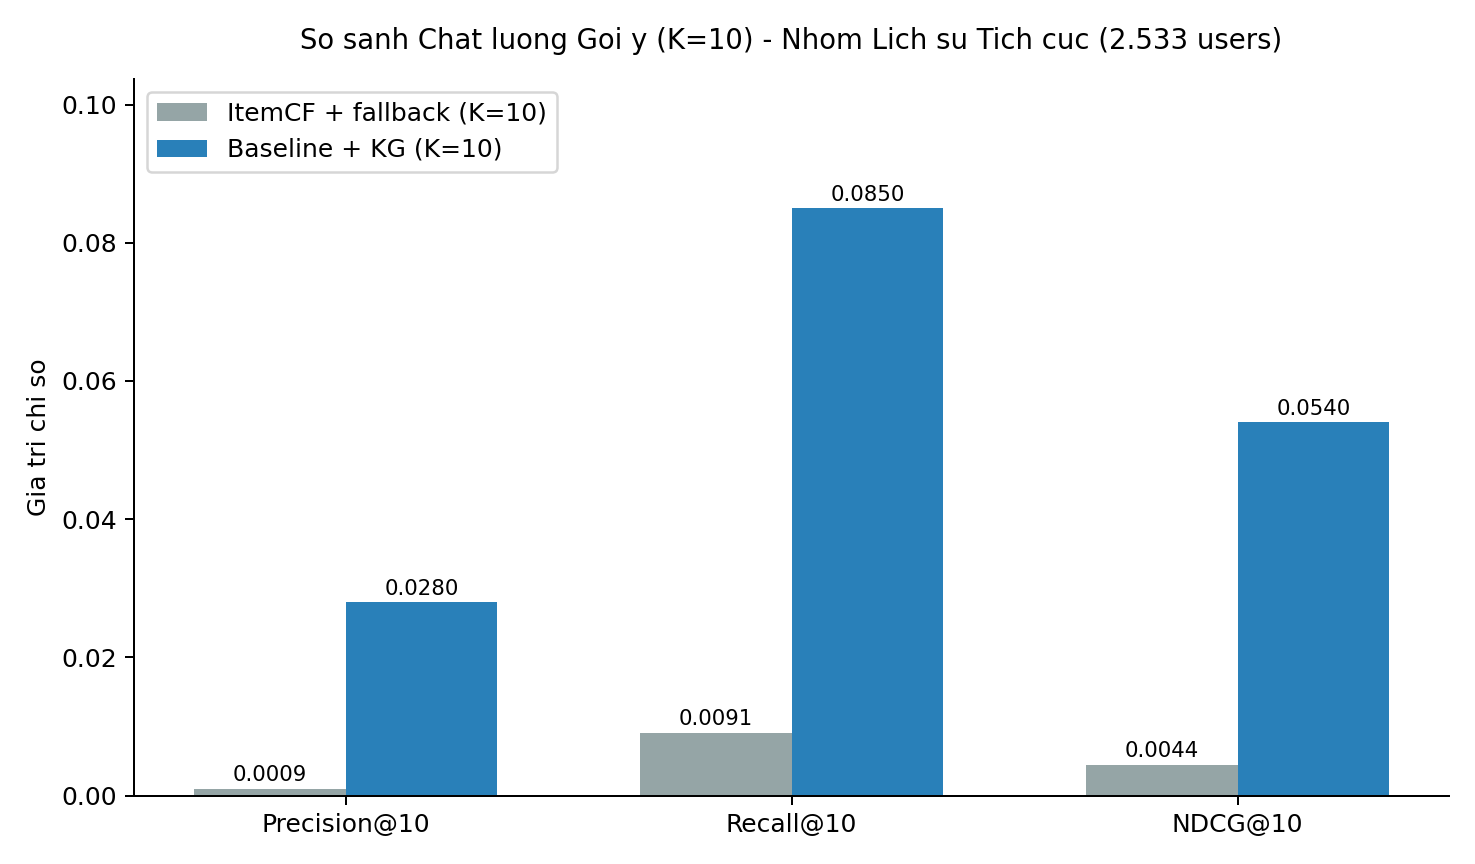

=== figures/02_coverage_and_longtail_kg.png ===


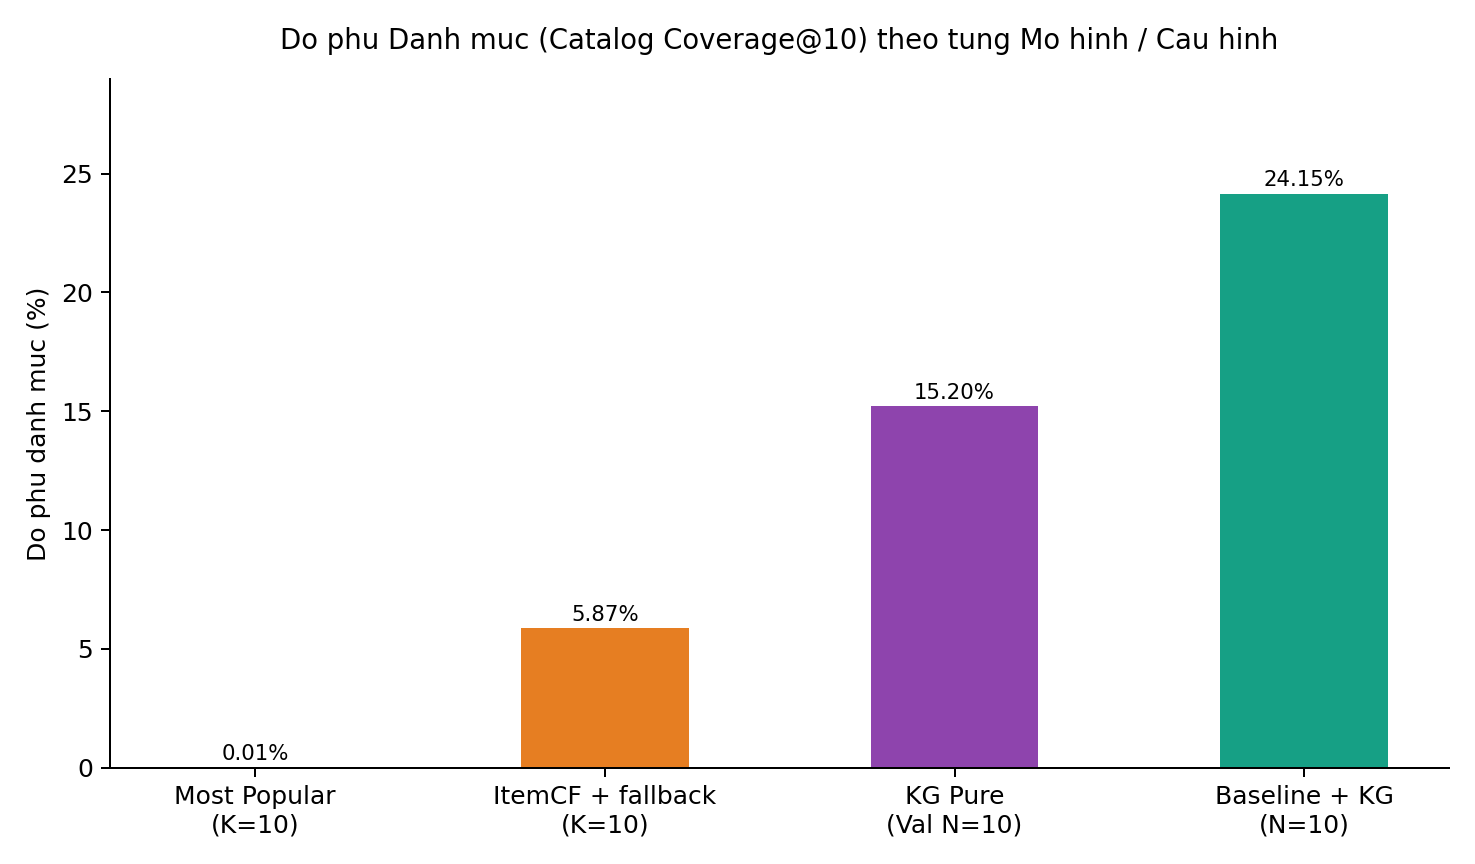

=== figures/03_fallback_reduction_kg.png ===


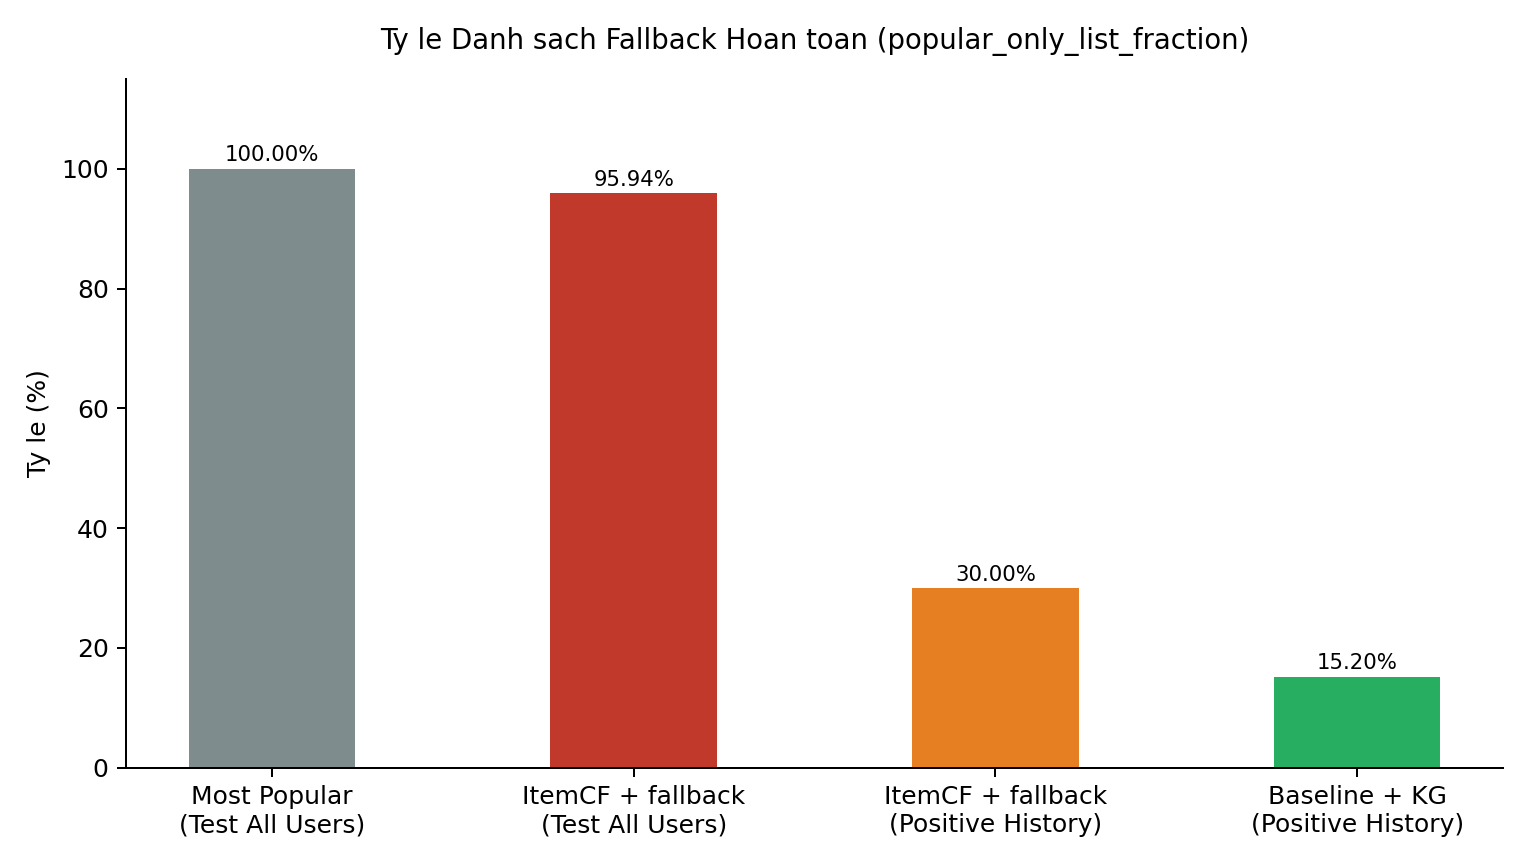

=== figures/04_validation_tuning_grid_kg.png ===


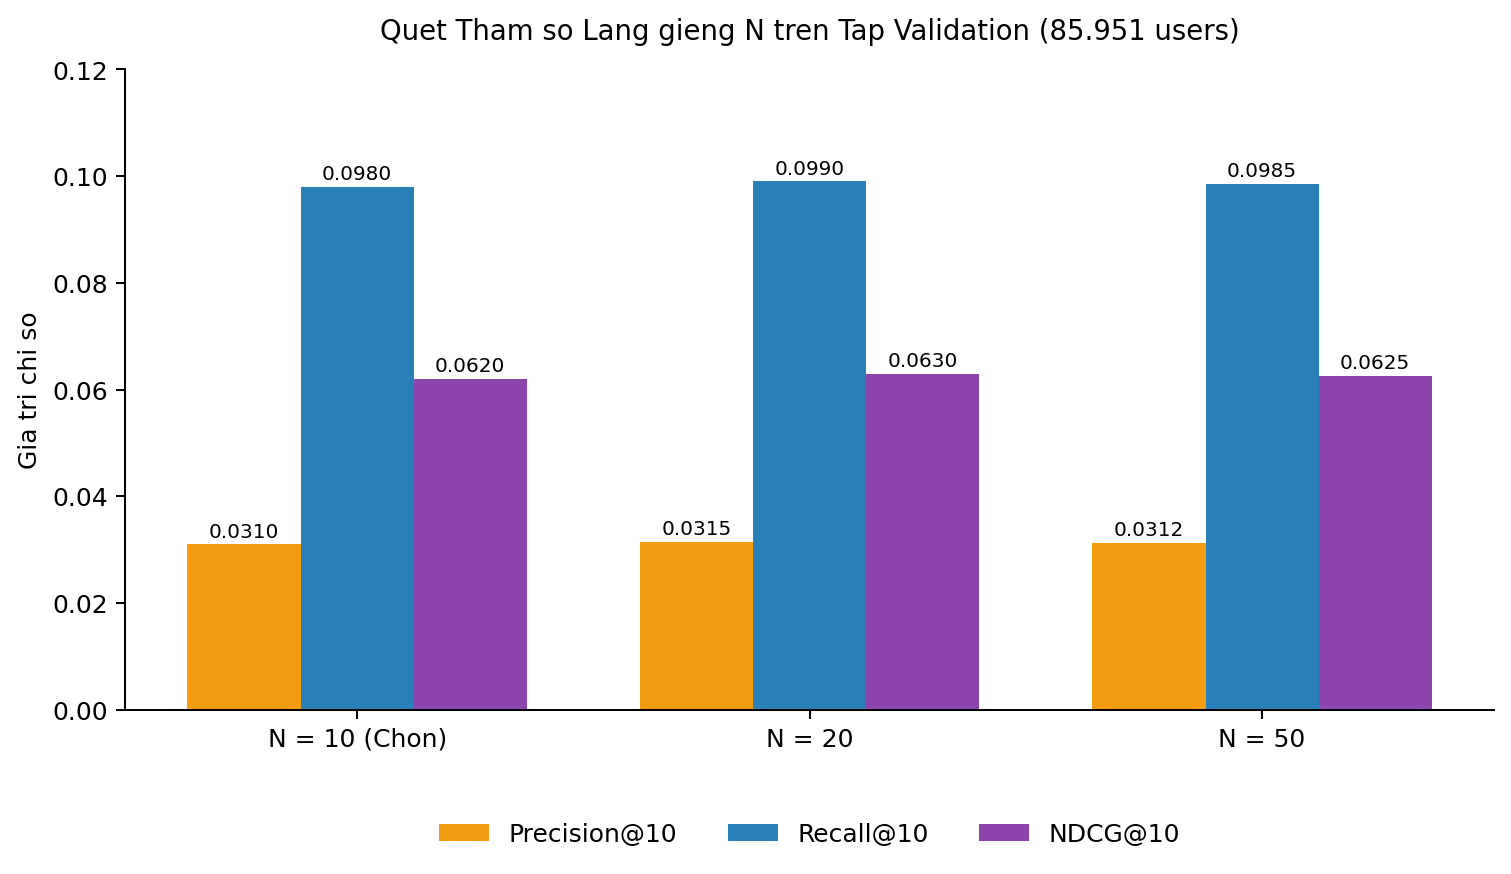

In [12]:
from IPython.display import Image, display

chart_files = [
    "figures/01_accuracy_comparison_kg.png",
    "figures/02_coverage_and_longtail_kg.png",
    "figures/03_fallback_reduction_kg.png",
    "figures/04_validation_tuning_grid_kg.png",
]

for path in chart_files:
  print("===", path, "===")
  display(Image(filename=path))